# Hands-on 22 (Bab 9): Deteksi Anomali Arus Listrik dengan Isolation Forest

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* (Onno W. Purbo), Bab 9.

Isolation Forest membangun baseline perilaku normal dan menandai titik menyimpang
tanpa label. Dataset sintetis punya 15 anomali buatan dengan ground truth untuk evaluasi.

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /home/sandbox/iot-ml-book


## 1. Generate Dataset Arus + Anomali

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/generate_current_anomaly_dataset.py"], capture_output=True, text=True)
print(r.stdout)

Dataset arus listrik disimpan ke: data/synthetic/current_sensor_anomaly.csv
            timestamp device_id  ...  power_watt  ground_truth_anomaly
0 2026-01-01 00:00:00   meter01  ...     1378.69                     0
1 2026-01-01 00:10:00   meter01  ...     1220.32                     0
2 2026-01-01 00:20:00   meter01  ...     1388.79                     0
3 2026-01-01 00:30:00   meter01  ...     1394.30                     0
4 2026-01-01 00:40:00   meter01  ...     1060.70                     0

[5 rows x 6 columns]
Jumlah anomali buatan: 15



## 2. Isolation Forest

=== Hasil Isolation Forest ===
iforest_anomaly
0    485
1     15
Name: count, dtype: int64
Figure(1200x500)



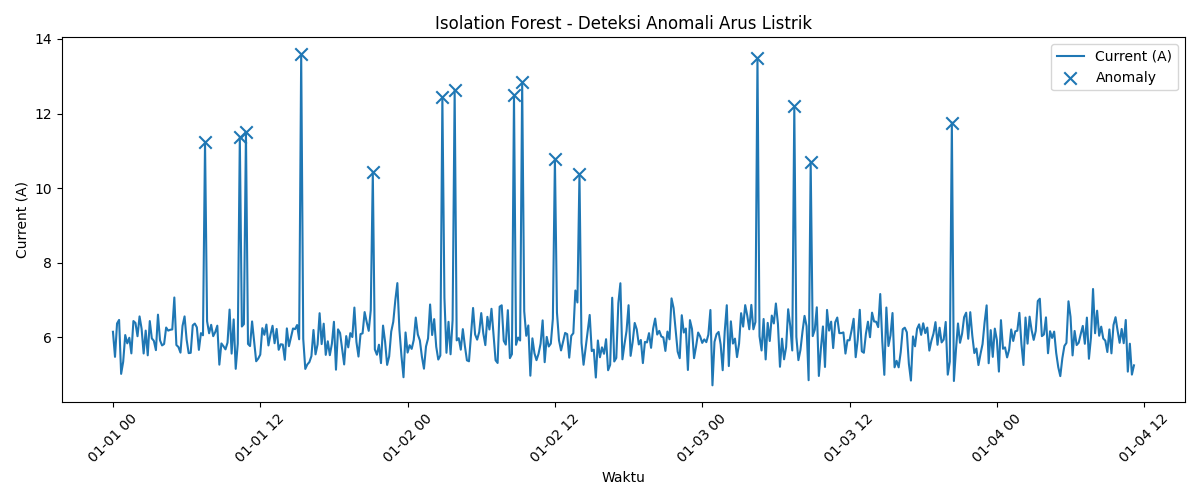

In [3]:
r = subprocess.run([sys.executable, "scripts/isolation_forest_current.py"], capture_output=True, text=True)
print(r.stdout)
from IPython.display import Image
Image("outputs/figures/current_iforest_anomaly.png")

## 3. Evaluasi terhadap Ground Truth

In [4]:
r = subprocess.run([sys.executable, "scripts/evaluate_iforest_current.py"], capture_output=True, text=True)
print(r.stdout)

=== Evaluasi Isolation Forest vs Ground Truth Sintetis ===
Confusion Matrix:
[[485   0]
 [  0  15]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       485
           1       1.00      1.00      1.00        15

    accuracy                           1.00       500
   macro avg       1.00      1.00      1.00       500
weighted avg       1.00      1.00      1.00       500




## Penutup

Dengan contamination=0.03 (15 dari 500 titik), Isolation Forest menandai persis 15
anomali buatan: precision, recall, dan F1 = 1.00 untuk kelas anomaly. Ini kasus ideal
karena lonjakan 4-8 A sangat jauh dari baseline (6.0 +/- 0.5 A); pada data nyata,
contamination perlu disetel dan hasil diverifikasi manual. Hasil tersimpan di
`outputs/reports/current_iforest_results.csv`.

## Catatan dari buku: pengamatan, variasi, dan latihan

Bagian berikut disalin dari buku (Hands-on 24 dalam urutan buku) sebagai panduan pengamatan dan latihan mandiri setelah menjalankan notebook ini.

### 5. Evaluasi sederhana terhadap ground truth sintetis

Walaupun Isolation Forest bersifat unsupervised, pada dataset sintetis kita bisa
membandingkan hasilnya dengan anomali buatan.
Buat file scripts/evaluate_iforest_current.py:
from pathlib import Path
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix
INPUT_PATH = Path("outputs/reports/current_iforest_results.csv")
df = pd.read_csv(INPUT_PATH)
y_true = df["ground_truth_anomaly"]
y_pred = df["iforest_anomaly"]
print("=== Evaluasi Isolation Forest vs Ground Truth Sintetis ===")
print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))
print("\nClassification Report:")
print(classification_report(y_true, y_pred, zero_division=0))

Jalankan:
python scripts/evaluate_iforest_current.py

Catatan penting
Evaluasi seperti ini hanya mungkin karena kita sengaja membuat ground truth
sintetis. Di dunia nyata, anomaly detection sering tidak punya label
sempurna. Maka hasil model harus dilihat juga melalui visualisasi, domain
knowledge, dan inspeksi operasional.